# Monte-Carlo uncertainties for Hugoniot fits



In [1]:
%%capture 
## This cell loads the modules, data, and EOS parameters
## capture magic function hides the output; comment out to see diagnostic info during data load
## Run executable notebook for output

%run -i scripts/set_paths
%run -i scripts/load_modules
%run -i scripts/load_silica_data
%run -i scripts/define_mc
%run -i scripts/define_eos
%run -i scripts/calibrate_decaying_shocks.py
%run -i scripts/load_vapor_domes.py
%run -i scripts/load_liquid_model.py
%run -i scripts/load_solid_models.py
%run -i scripts/intersection.py # intersection function
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors

# this notebook's figure name tag
tag = 'MCC-'


In [2]:
from dataclasses import dataclass, field, fields
import scipy as sp
from scipy import linalg

# https://realpython.com/python-data-classes/
@dataclass
class HPeos_MC:
    """ Data class for Monte-Carlo Hugoniot Uncertainties.
        sts 2025-07-24
    """
    npts:        int = 0      # number of MC points for each independent up
    up_ind:      np.ndarray = field(default_factory=lambda: np.zeros(0)) # independent up
    rho0:        np.ndarray = field(default_factory=lambda: np.zeros(0))  
    up:          np.ndarray = field(default_factory=lambda: np.zeros(0))
    us:          np.ndarray = field(default_factory=lambda: np.zeros(0))  
    p:           np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho:         np.ndarray = field(default_factory=lambda: np.zeros(0))  
    t:           np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho0_mean:     np.ndarray = field(default_factory=lambda: np.zeros(0))  
    us_mean:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    p_mean:       np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho_mean:     np.ndarray = field(default_factory=lambda: np.zeros(0))  
    t_mean:       np.ndarray = field(default_factory=lambda: np.zeros(0))
    rho0_std:     np.ndarray = field(default_factory=lambda: np.zeros(0))  
    us_std:      np.ndarray = field(default_factory=lambda: np.zeros(0))  
    p_std:       np.ndarray = field(default_factory=lambda: np.zeros(0))  
    rho_std:     np.ndarray = field(default_factory=lambda: np.zeros(0))  
    t_std:       np.ndarray = field(default_factory=lambda: np.zeros(0))
    def __iter__(self):
        '''Needed to convert class object into dictionary.'''
        for key in self.__dict__:
            yield key, getattr(self,key)
    def calcPrho(self):
        ''' Calculate pressure and density values from particle velocity and shock velocity values. No error propagation. '''
        self.p = self.rho0 * self.us * self.up
        self.rho = 1./( (1./self.rho0) * (1. - self.up/self.us) )
    def calcMC(self,upus_fit,ust_fit,verbose=True):
        ''' Calculate MC uncertainties from up-us and us-temp fits. '''

        # need to be set prior to calling calcMC
        if self.npts == 0:
            print('Need to set number of MC points for each independent up.')
            return
        if len(self.up_ind) == 0:
            print('Need to define independent array for up.')
            return

        nupind = len(self.up_ind)
        nsteps = self.npts
        if verbose:
            print('*** Starting Monte-Carlo uncertainty calculation ***')
            print('Number of particle velocity points = ',nupind)
            print('Number of MC iterations for each up = ',nsteps)
        count=0
        if nupind > 10:
            i_print = np.round(nupind/10) # print about 10 diagnostic steps per run
        ###========================================================================
        # BEGIN SECTION WITH GENERIC VARIABLE NAMES SO CAN BE RUN FOR DIFFERENT MATERIALS
        
        # us-up fit
        # The Cholesky decomposition is commonly used in the Monte Carlo method for simulating systems with multiple correlated variables. The covariance matrix is decomposed to give the lower-triangular L. Applying this to a vector of uncorrelated samples u produces a sample vector Lu with the covariance properties of the system being modeled.
        dat_lmat_upus = sp.linalg.cholesky(upus_fit.cov,lower=True) 
        dat_lmat_ust = sp.linalg.cholesky(ust_fit.cov,lower=True) 
        
        self.us_mean   = np.zeros(nupind)
        self.p_mean    = np.zeros(nupind)
        self.rho_mean  = np.zeros(nupind)
        self.rho0_mean  = np.zeros(nupind)
        self.t_mean    = np.zeros(nupind)
        self.us_std   = np.zeros(nupind)
        self.p_std    = np.zeros(nupind)
        self.rho_std  = np.zeros(nupind)
        self.rho0_std  = np.zeros(nupind)
        self.t_std    = np.zeros(nupind)

        if verbose:
            print('Monte-Carlo error bar calculation using these us-up and us-temp fits:')
            print(upus_fit.filename)
            print('Coefs = ',upus_fit.a)
            print(ust_fit.filename)
            print('Coefs = ',ust_fit.a)
        
        # loop over independent variable up
        for iup in range(len(self.up_ind)):
            # set independent variable
            self.up   = np.zeros(nsteps)+self.up_ind[iup]
            # set up MC variables
            self.rho0 = np.zeros(nsteps)
            self.us   = np.zeros(nsteps)
            self.p    = np.zeros(nsteps)
            self.rho  = np.zeros(nsteps)
            self.t    = np.zeros(nsteps)
        
            # MC steps for each independent variable
            temp_fit = hp.HPeos_Fit()
        
            # up -> Us, P, V points
            # Us -> T points
            for imc in range(nsteps):      
                # uncertainty on initial density
                self.rho0[imc] = upus_fit.rho_ref + upus_fit.rho_ref_std*np.random.randn()
        
                # uncertainty on curve fit to us-up
                ncoefs = len(upus_fit.a)
                temp_mat=np.random.randn(ncoefs)
                bmat=np.matmul(dat_lmat_upus,temp_mat)
                
                a_mc = np.zeros(ncoefs)
                for ia in range(ncoefs):
                    a_mc[ia] = upus_fit.a[ia]+bmat[ia]
                # fill generic fit data structure
                temp_fit.a = a_mc
                temp_fit.curvetype = upus_fit.curvetype
                self.us[imc]=temp_fit.calcf(self.up[imc])
                #print(temp_fit.a)
        
                # uncertainty on curve fit to T-us
                ncoefs = len(ust_fit.a)
                temp_mat=np.random.randn(ncoefs)
                bmat=np.matmul(dat_lmat_ust,temp_mat)
                
                a_mc = np.zeros(ncoefs)
                for ia in range(ncoefs):
                    a_mc[ia] = ust_fit.a[ia]+bmat[ia]
                # fill generic fit data structure
                temp_fit.a = a_mc
                temp_fit.curvetype = ust_fit.curvetype
                self.t[imc]=temp_fit.calcf(self.us[imc])
                #print(temp_fit.a)
                
            # for each independent variable
            # calculate P and rho for the MC batch
            self.calcPrho()
            # The mean and std for each MC batch
            self.rho0_mean[iup] = np.mean(self.rho0)
            self.rho0_std[iup] = np.std(self.rho0)
            self.us_mean[iup] = np.mean(self.us)
            self.us_std[iup] = np.std(self.us)
            self.p_mean[iup] = np.mean(self.p)
            self.p_std[iup] = np.std(self.p)
            self.rho_mean[iup] = np.mean(self.rho)
            self.rho_std[iup] = np.std(self.rho)
            self.t_mean[iup] = np.mean(self.t)
            self.t_std[iup] = np.std(self.t)


            if verbose:
                # print about 10 diagnostic steps per run
                if (count % i_print) == 0:
                    print(count,self.up_ind[iup],self.us_mean[iup],self.us_std[iup],upus_fit.calcf(self.up_ind[iup]),self.rho0_mean[iup],self.rho0_std[iup],self.p_mean[iup],self.rho_mean[iup],self.t_mean[iup],self.t_std[iup])
                count += 1
        if 1:
            # free up memory
            steps = 1
            self.rho0 = np.zeros(steps)
            self.us   = np.zeros(steps)
            self.p    = np.zeros(steps)
            self.rho  = np.zeros(steps)
            self.t    = np.zeros(steps)
                

## Fused silica Hugoniot - liquid region sensitivity tests

In [3]:
## Fused silica PVT Hugoniot
print('Reference density = ',fs_fit_liq0.rho_ref)
print('Reference density uncertainty = ',fs_fit_liq0.rho_ref_std)
upus_fit = deepcopy(fs_fit_liq0)
upus_fit.rho_ref_std = .02
print('Using rho0 std = 0.02 g/cm3')
ust_fit = deepcopy(fs_fitTus_liq0)
## define_eos.py range fs_hug_liq.up = np.arange(3,20,.001) # km/s
upmin=3
upmax=20


Reference density =  2.204
Reference density uncertainty =  0.0
Using rho0 std = 0.02 g/cm3


In [4]:
import time

#print(len(fs_hug_liq.up))
## Fused silica PVT Hugoniot
print('Fused silia PTV Hugoniot Monte-Carlo uncertainties')
nsteps = [10,100,500,1000,2000]
nupind = 500#200
print('number of up points = ',nupind)
mc_list =  []
for ii in range(len(nsteps)):
    start_time = time.perf_counter()

    dat_mc = HPeos_MC()
    dat_mc.npts = nsteps[ii]
    
    mcuparr = np.linspace(upmin,upmax,nupind)
    dat_mc.up_ind = mcuparr 
    dat_mc.calcMC(upus_fit,ust_fit,verbose=False)

    end_time = time.perf_counter()
    print('Time: ',nsteps[ii],end_time - start_time)

    mc_list.append(deepcopy(dat_mc))
    

Fused silia PTV Hugoniot Monte-Carlo uncertainties
number of up points =  500
Time:  10 0.06238279212266207
Time:  100 0.37593312514945865
Time:  500 1.7866363753564656
Time:  1000 3.5034579588100314
Time:  2000 6.984423084184527


<Figure size 800x600 with 0 Axes>

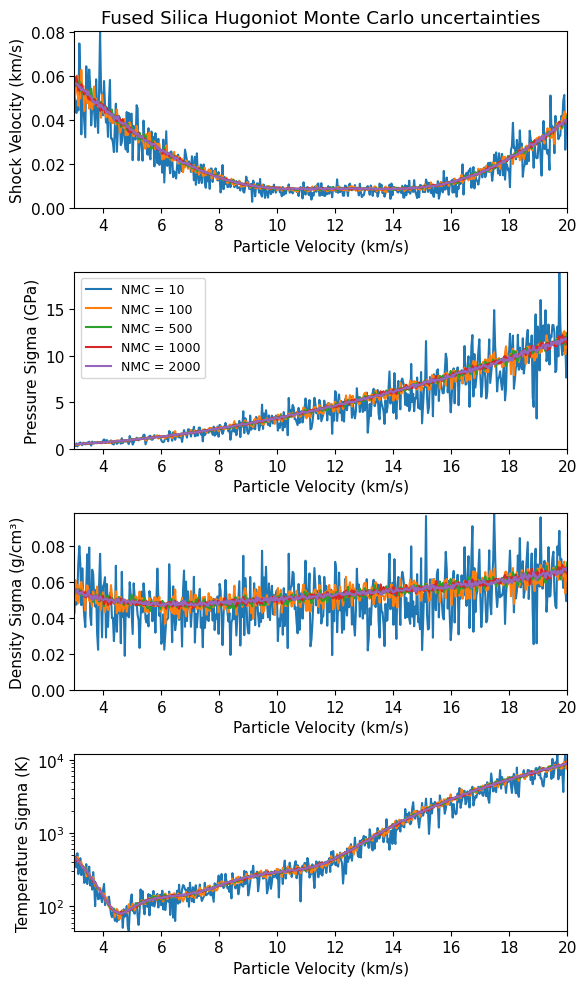

In [5]:
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
fig, ax = plt.subplots(4, 1,figsize=fsize5)
plt.rcParams['lines.markersize'] = mks

maxp=0
maxr=0
maxt=0
mint=10000
maxus=0

minup = min(mc_list[0].up_ind)
maxup = max(mc_list[0].up_ind)
for ii in range(len(mc_list)):

    xi=0
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].us_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].us_std)>maxus:
        maxus=max(mc_list[ii].us_std)
        
    xi=1
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].p_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].p_std)>maxp:
        maxp=max(mc_list[ii].p_std)
    xi=2
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].rho_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].rho_std)>maxr:
        maxr=max(mc_list[ii].rho_std)    
    xi=3
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].t_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].t_std)>maxt:
        maxt=max(mc_list[ii].t_std)       
    if min(mc_list[ii].t_std)<mint:
        mint=min(mc_list[ii].t_std)       

xi=0
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxus)
ax[xi].set_ylabel('Shock Velocity (km/s)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].set_title('Fused Silica Hugoniot Monte Carlo uncertainties')


xi=1
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxp)
ax[xi].set_ylabel('Pressure Sigma (GPa)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].legend(fontsize=lfss)

xi=2
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxr)
ax[xi].set_ylabel('Density Sigma (g/cm³)')
ax[xi].set_xlabel('Particle Velocity (km/s)')


xi=3
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(mint,maxt)
ax[xi].set_yscale('log')
ax[xi].set_ylabel('Temperature Sigma (K)')
ax[xi].set_xlabel('Particle Velocity (km/s)')



fig.tight_layout()
plt.savefig(outputfigpath+tag+'fs-mc-sensitivity.pdf')
plt.show()

In [6]:
## After picking the desired resolution, interpolate the uncertainties into the master hugoniot array
## This is for fast loading. Can modify as desired using the MC hpeos module function

# choose index for interpolation
imc=3
print('MC nup, nsteps=',len(mc_list[imc].up_ind),mc_list[imc].npts)
fs_hug_liq.us_std = np.interp(fs_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].us_std)
fs_hug_liq.P_std = np.interp(fs_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].p_std)
fs_hug_liq.T_std = np.interp(fs_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].t_std)
fs_hug_liq.rho_std = np.interp(fs_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].rho_std)


MC nup, nsteps= 500 1000


<Figure size 800x600 with 0 Axes>

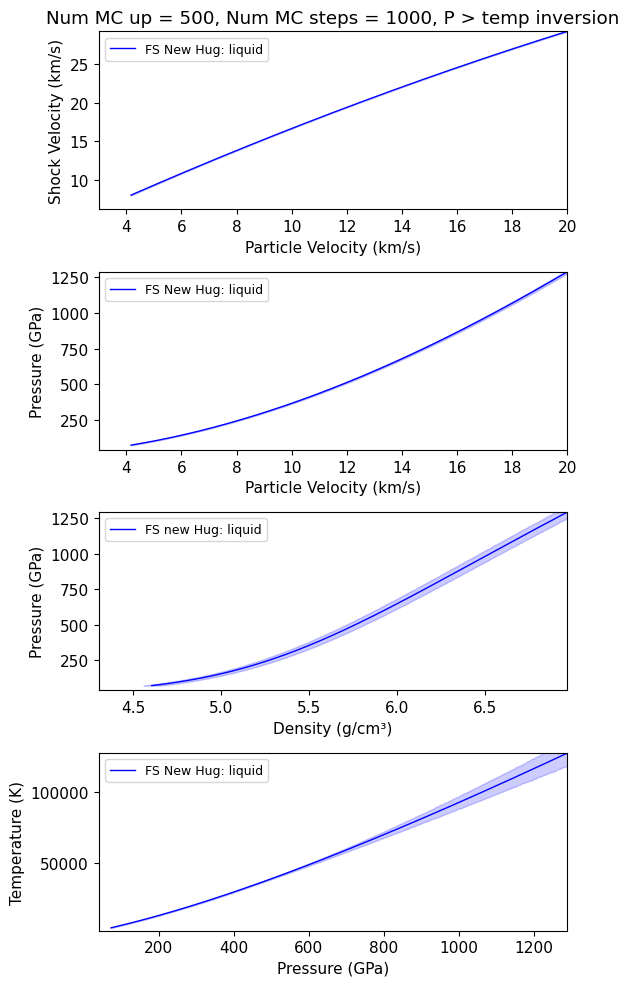

In [7]:
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
fig, ax = plt.subplots(4, 1,figsize=fsize5)
plt.rcParams['lines.markersize'] = mks


fs_mc = mc_list[3]

xi=0
ind = np.where(fs_hug_liq.P > fs_wiggle_P2)
ax[xi].plot(fs_hug_liq.up[ind],fs_hug_liq.us[ind],'b-',label='FS New Hug: liquid',linewidth=1)
ax[xi].fill_between(fs_hug_liq.up[ind],fs_hug_liq.us[ind]-fs_hug_liq.us_std[ind],fs_hug_liq.us[ind]+fs_hug_liq.us_std[ind],color='blue',alpha=.2)
#ind = np.where(fs_mc.p_mean > fs_wiggle_P2)
#ax[xi].fill_between(fs_mc.up_ind[ind],fs_mc.p_mean[ind]-fs_mc.p_std[ind],fs_mc.p_mean[ind]+fs_mc.p_std[ind],color='black',alpha=.2)
ax[xi].set_xlim(min(fs_mc.up_ind),max(fs_mc.up_ind))
ax[xi].set_ylim(min(fs_mc.us_mean),max(fs_mc.us_mean))
ax[xi].set_ylabel('Shock Velocity (km/s)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].set_title('Num MC up = '+str(len(fs_mc.up_ind))+', Num MC steps = '+str(fs_mc.npts)+', P > temp inversion')
ax[xi].legend(fontsize=lfss)

xi=1
ind = np.where(fs_hug_liq.P > fs_wiggle_P2)
ax[xi].plot(fs_hug_liq.up[ind],fs_hug_liq.P[ind],'b-',label='FS New Hug: liquid',linewidth=1)
ax[xi].fill_between(fs_hug_liq.up[ind],fs_hug_liq.P[ind]-fs_hug_liq.P_std[ind],fs_hug_liq.P[ind]+fs_hug_liq.P_std[ind],color='blue',alpha=.2)
#ind = np.where(fs_mc.p_mean > fs_wiggle_P2)
#ax[xi].fill_between(fs_mc.up_ind[ind],fs_mc.p_mean[ind]-fs_mc.p_std[ind],fs_mc.p_mean[ind]+fs_mc.p_std[ind],color='black',alpha=.2)
ax[xi].set_xlim(min(fs_mc.up_ind),max(fs_mc.up_ind))
ax[xi].set_ylim(min(fs_mc.p_mean),max(fs_mc.p_mean))
ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
#ax[xi].set_title('Num MC up = '+str(len(fs_mc.up_ind))+', Num MC steps = '+str(fs_mc.npts)+', P > temp inversion')
ax[xi].legend(fontsize=lfss)

xi=2
ind = np.where(fs_hug_liq.P > fs_wiggle_P2)
ax[xi].plot(fs_hug_liq.rho[ind],fs_hug_liq.P[ind],'b-',linewidth=1,label='FS new Hug: liquid')
ax[xi].fill_betweenx(fs_hug_liq.P[ind],fs_hug_liq.rho[ind]-fs_hug_liq.rho_std[ind],fs_hug_liq.rho[ind]+fs_hug_liq.rho_std[ind],color='blue',alpha=.2)
#ind = np.where(fs_mc.p_mean > fs_wiggle_P2)
#ax[xi].fill_betweenx(fs_mc.p_mean[ind],fs_mc.rho_mean[ind]-fs_mc.rho_std[ind],fs_mc.rho_mean[ind]+fs_mc.rho_std[ind],color='black',alpha=.2)

ax[xi].set_xlim(min(fs_mc.rho_mean),max(fs_mc.rho_mean))
ax[xi].set_ylim(min(fs_mc.p_mean),max(fs_mc.p_mean))
ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Density (g/cm³)')
ax[xi].legend(fontsize=lfss)


xi=3
ind = np.where(fs_hug_liq.P > fs_wiggle_P2)
ax[xi].plot(fs_hug_liq.P[ind],fs_hug_liq.T[ind],'b-',label='FS New Hug: liquid',linewidth=1)
ax[xi].fill_between(fs_hug_liq.P[ind],fs_hug_liq.T[ind]-fs_hug_liq.T_std[ind],fs_hug_liq.T[ind]+fs_hug_liq.T_std[ind],color='blue',alpha=.2)

#ind = np.where(fs_mc.p_mean > fs_wiggle_P2)
#ax[xi].fill_between(fs_mc.p_mean[ind],fs_mc.t_mean[ind]-fs_mc.t_std[ind],fs_mc.t_mean[ind]+fs_mc.t_std[ind],color='black',alpha=0.2)

ax[xi].set_ylim(min(fs_mc.t_mean),max(fs_mc.t_mean))
ax[xi].set_xlim(min(fs_mc.p_mean),max(fs_mc.p_mean))

ax[xi].set_xlabel('Pressure (GPa)')
ax[xi].set_ylabel('Temperature (K)')
ax[xi].legend(fontsize=lfss)

fig.tight_layout()
plt.savefig(outputfigpath+tag+'fs-mc-uncertainties.pdf')
plt.show()

## Fused silica Hugoniot - solid regions sensitivity tests

## Quartz Hugoniot - liquid region sensitivity tests

In [8]:
## Alpha-quartz PVT Hugoniot
print('Reference density = ',qtz_fit_liq0.rho_ref)
print('Reference density uncertainty = ',qtz_fit_liq0.rho_ref_std)
upus_fit = deepcopy(qtz_fit_liq0)
upus_fit.rho_ref_std = .01
print('Using rho0 std = 0.01 g/cm3')
ust_fit = deepcopy(qtz_fitTus_liq0)
## define_eos.py range fs_hug_liq.up = np.arange(3,20,.001) # km/s
upmin=3
upmax=22


Reference density =  2.65
Reference density uncertainty =  0.0
Using rho0 std = 0.01 g/cm3


In [9]:
import time

#print(len(fs_hug_liq.up))
## Fused silica PVT Hugoniot
print('Quartz PTV Hugoniot Monte-Carlo uncertainties')
nsteps = [10,100,500,1000,2000]
nupind = 500#200
print('number of up points = ',nupind)
mc_list =  []
for ii in range(len(nsteps)):
    start_time = time.perf_counter()

    dat_mc = HPeos_MC()
    dat_mc.npts = nsteps[ii]
    
    mcuparr = np.linspace(upmin,upmax,nupind)
    dat_mc.up_ind = mcuparr 
    dat_mc.calcMC(upus_fit,ust_fit,verbose=False)

    end_time = time.perf_counter()
    print('Time: ',nsteps[ii],end_time - start_time)

    mc_list.append(deepcopy(dat_mc))
    

Quartz PTV Hugoniot Monte-Carlo uncertainties
number of up points =  500
Time:  10 0.06529741687700152
Time:  100 0.4296152498573065
Time:  500 2.0035803746432066
Time:  1000 3.9130108328536153
Time:  2000 8.10020604217425


<Figure size 800x600 with 0 Axes>

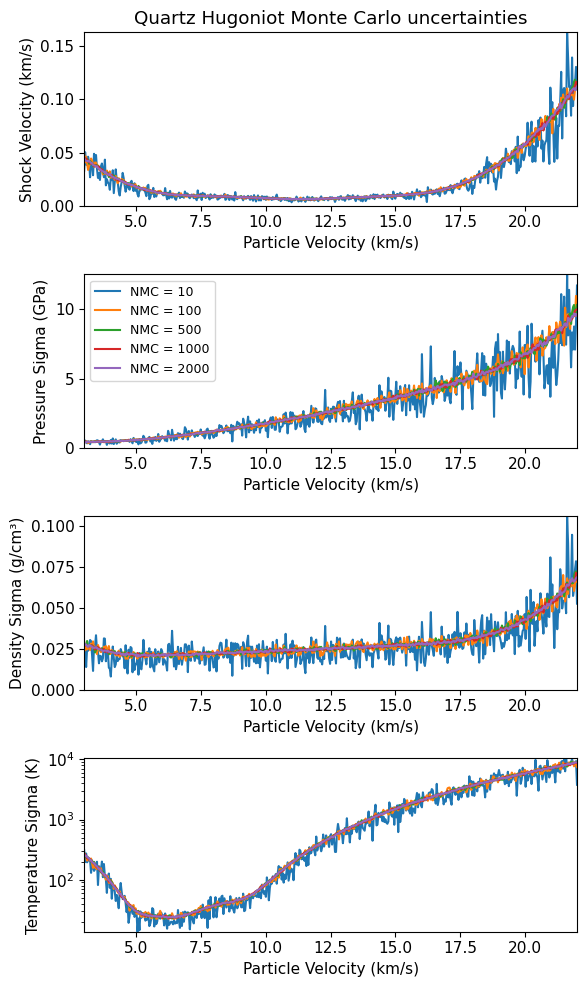

In [10]:
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
fig, ax = plt.subplots(4, 1,figsize=fsize5)
plt.rcParams['lines.markersize'] = mks

maxp=0
maxr=0
maxt=0
mint=10000
maxus=0

minup = min(mc_list[0].up_ind)
maxup = max(mc_list[0].up_ind)
for ii in range(len(mc_list)):

    xi=0
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].us_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].us_std)>maxus:
        maxus=max(mc_list[ii].us_std)
        
    xi=1
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].p_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].p_std)>maxp:
        maxp=max(mc_list[ii].p_std)
    xi=2
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].rho_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].rho_std)>maxr:
        maxr=max(mc_list[ii].rho_std)    
    xi=3
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].t_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].t_std)>maxt:
        maxt=max(mc_list[ii].t_std)       
    if min(mc_list[ii].t_std)<mint:
        mint=min(mc_list[ii].t_std)       

xi=0
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxus)
ax[xi].set_ylabel('Shock Velocity (km/s)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].set_title('Quartz Hugoniot Monte Carlo uncertainties')


xi=1
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxp)
ax[xi].set_ylabel('Pressure Sigma (GPa)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].legend(fontsize=lfss)

xi=2
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxr)
ax[xi].set_ylabel('Density Sigma (g/cm³)')
ax[xi].set_xlabel('Particle Velocity (km/s)')


xi=3
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(mint,maxt)
ax[xi].set_yscale('log')
ax[xi].set_ylabel('Temperature Sigma (K)')
ax[xi].set_xlabel('Particle Velocity (km/s)')



fig.tight_layout()
plt.savefig(outputfigpath+tag+'qtz-mc-sensitivity.pdf')
plt.show()

In [11]:
## After picking the desired resolution, interpolate the uncertainties into the master hugoniot array
## This is for fast loading. Can modify as desired using the MC hpeos module function

# choose index for interpolation
imc=3
print('MC nup, nsteps=',len(mc_list[imc].up_ind),mc_list[imc].npts)
qtz_hug_liq.us_std = np.interp(qtz_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].us_std)
qtz_hug_liq.P_std = np.interp(qtz_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].p_std)
qtz_hug_liq.T_std = np.interp(qtz_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].t_std)
qtz_hug_liq.rho_std = np.interp(qtz_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].rho_std)


MC nup, nsteps= 500 1000


<Figure size 800x600 with 0 Axes>

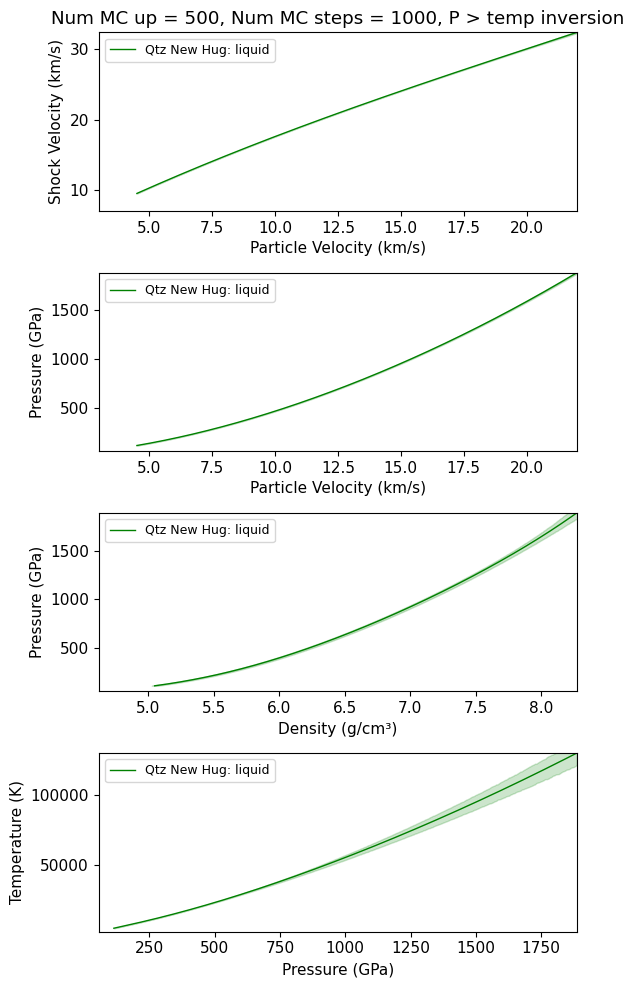

In [12]:
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
fig, ax = plt.subplots(4, 1,figsize=fsize5)
plt.rcParams['lines.markersize'] = mks


qtz_mc = mc_list[3]

xi=0
ind = np.where(qtz_hug_liq.P > qtz_wiggle_P2)
ax[xi].plot(qtz_hug_liq.up[ind],qtz_hug_liq.us[ind],'g-',label='Qtz New Hug: liquid',linewidth=1)
ax[xi].fill_between(qtz_hug_liq.up[ind],qtz_hug_liq.us[ind]-qtz_hug_liq.us_std[ind],qtz_hug_liq.us[ind]+qtz_hug_liq.us_std[ind],color='green',alpha=.2)
#ind = np.where(qtz_mc.p_mean > qtz_wiggle_P2)
#ax[xi].fill_between(qtz_mc.up_ind[ind],qtz_mc.p_mean[ind]-qtz_mc.p_std[ind],qtz_mc.p_mean[ind]+qtz_mc.p_std[ind],color='black',alpha=.2)
ax[xi].set_xlim(min(qtz_mc.up_ind),max(qtz_mc.up_ind))
ax[xi].set_ylim(min(qtz_mc.us_mean),max(qtz_mc.us_mean))
ax[xi].set_ylabel('Shock Velocity (km/s)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].set_title('Num MC up = '+str(len(qtz_mc.up_ind))+', Num MC steps = '+str(qtz_mc.npts)+', P > temp inversion')
ax[xi].legend(fontsize=lfss)

xi=1
ind = np.where(qtz_hug_liq.P > qtz_wiggle_P2)
ax[xi].plot(qtz_hug_liq.up[ind],qtz_hug_liq.P[ind],'g-',label='Qtz New Hug: liquid',linewidth=1)
ax[xi].fill_between(qtz_hug_liq.up[ind],qtz_hug_liq.P[ind]-qtz_hug_liq.P_std[ind],qtz_hug_liq.P[ind]+qtz_hug_liq.P_std[ind],color='green',alpha=.2)
#ind = np.where(qtz_mc.p_mean > qtz_wiggle_P2)
#ax[xi].fill_between(qtz_mc.up_ind[ind],qtz_mc.p_mean[ind]-qtz_mc.p_std[ind],qtz_mc.p_mean[ind]+qtz_mc.p_std[ind],color='black',alpha=.2)
ax[xi].set_xlim(min(qtz_mc.up_ind),max(qtz_mc.up_ind))
ax[xi].set_ylim(min(qtz_mc.p_mean),max(qtz_mc.p_mean))
ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
#ax[xi].set_title('Num MC up = '+str(len(qtz_mc.up_ind))+', Num MC steps = '+str(qtz_mc.npts)+', P > temp inversion')
ax[xi].legend(fontsize=lfss)

xi=2
ind = np.where(qtz_hug_liq.P > qtz_wiggle_P2)
ax[xi].plot(qtz_hug_liq.rho[ind],qtz_hug_liq.P[ind],'g-',linewidth=1,label='Qtz New Hug: liquid')
ax[xi].fill_betweenx(qtz_hug_liq.P[ind],qtz_hug_liq.rho[ind]-qtz_hug_liq.rho_std[ind],qtz_hug_liq.rho[ind]+qtz_hug_liq.rho_std[ind],color='green',alpha=.2)
#ind = np.where(qtz_mc.p_mean > qtz_wiggle_P2)
#ax[xi].fill_betweenx(qtz_mc.p_mean[ind],qtz_mc.rho_mean[ind]-qtz_mc.rho_std[ind],qtz_mc.rho_mean[ind]+qtz_mc.rho_std[ind],color='black',alpha=.2)

ax[xi].set_xlim(min(qtz_mc.rho_mean),max(qtz_mc.rho_mean))
ax[xi].set_ylim(min(qtz_mc.p_mean),max(qtz_mc.p_mean))
ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Density (g/cm³)')
ax[xi].legend(fontsize=lfss)


xi=3
ind = np.where(qtz_hug_liq.P > qtz_wiggle_P2)
ax[xi].plot(qtz_hug_liq.P[ind],qtz_hug_liq.T[ind],'g-',label='Qtz New Hug: liquid',linewidth=1)
ax[xi].fill_between(qtz_hug_liq.P[ind],qtz_hug_liq.T[ind]-qtz_hug_liq.T_std[ind],qtz_hug_liq.T[ind]+qtz_hug_liq.T_std[ind],color='green',alpha=.2)

#ind = np.where(qtz_mc.p_mean > qtz_wiggle_P2)
#ax[xi].fill_between(qtz_mc.p_mean[ind],qtz_mc.t_mean[ind]-qtz_mc.t_std[ind],qtz_mc.t_mean[ind]+qtz_mc.t_std[ind],color='black',alpha=0.2)

ax[xi].set_ylim(min(qtz_mc.t_mean),max(qtz_mc.t_mean))
ax[xi].set_xlim(min(qtz_mc.p_mean),max(qtz_mc.p_mean))

ax[xi].set_xlabel('Pressure (GPa)')
ax[xi].set_ylabel('Temperature (K)')
ax[xi].legend(fontsize=lfss)

fig.tight_layout()
plt.savefig(outputfigpath+tag+'qtz-mc-uncertainties.pdf')
plt.show()

## Coesite Hugoniot -- liquid region sensitivity tests

In [13]:
## Fused silica PVT Hugoniot
print('Reference density = ',cst_fit_liq0.rho_ref)
print('Reference density uncertainty = ',cst_fit_liq0.rho_ref_std)
upus_fit = deepcopy(cst_fit_liq0)
ust_fit = deepcopy(cst_fitTus_liq0)
## define_eos.py range cst_hug_liq.up = np.arange(4,14,.001) # km/s
upmin=4
upmax=14


Reference density =  2.92
Reference density uncertainty =  0.03


In [14]:
import time

print('Coesite PTV Hugoniot Monte-Carlo uncertainties')
nsteps = [10,100,500,1000,2000]
nupind = 500#200
print('number of up points = ',nupind)
mc_list =  []
for ii in range(len(nsteps)):
    start_time = time.perf_counter()

    dat_mc = HPeos_MC()
    dat_mc.npts = nsteps[ii]
    
    mcuparr = np.linspace(upmin,upmax,nupind)
    dat_mc.up_ind = mcuparr 
    dat_mc.calcMC(upus_fit,ust_fit,verbose=False)

    end_time = time.perf_counter()
    print('Time: ',nsteps[ii],end_time - start_time)

    mc_list.append(deepcopy(dat_mc))
    

Coesite PTV Hugoniot Monte-Carlo uncertainties
number of up points =  500
Time:  10 0.05955579085275531
Time:  100 0.31543929129838943
Time:  500 1.3413017080165446
Time:  1000 2.6527901249937713
Time:  2000 5.2430650419555604


<Figure size 800x600 with 0 Axes>

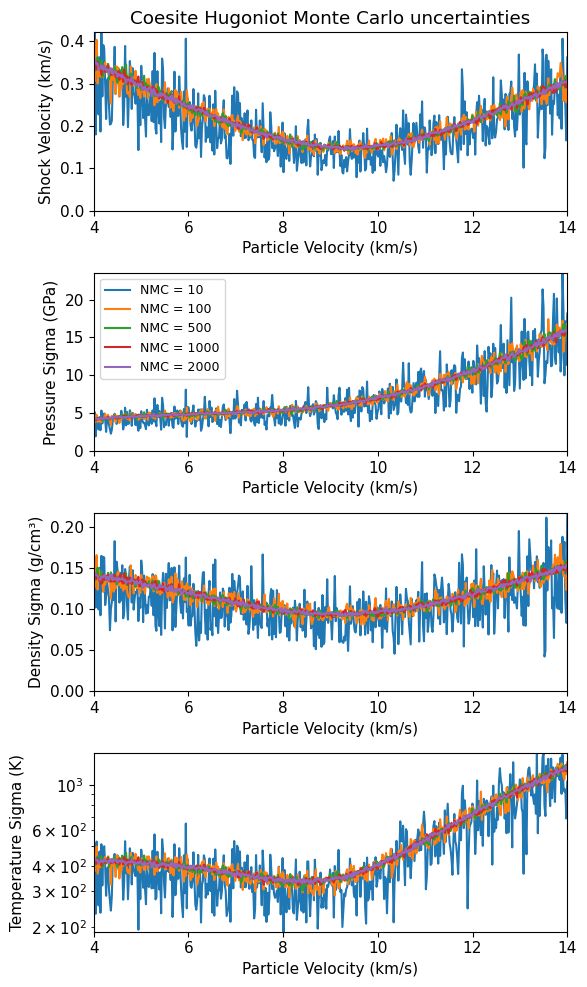

In [15]:
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
fig, ax = plt.subplots(4, 1,figsize=fsize5)
plt.rcParams['lines.markersize'] = mks

maxp=0
maxr=0
maxt=0
mint=10000
maxus=0

minup = min(mc_list[0].up_ind)
maxup = max(mc_list[0].up_ind)
for ii in range(len(mc_list)):

    xi=0
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].us_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].us_std)>maxus:
        maxus=max(mc_list[ii].us_std)
        
    xi=1
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].p_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].p_std)>maxp:
        maxp=max(mc_list[ii].p_std)
    xi=2
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].rho_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].rho_std)>maxr:
        maxr=max(mc_list[ii].rho_std)    
    xi=3
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].t_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].t_std)>maxt:
        maxt=max(mc_list[ii].t_std)       
    if min(mc_list[ii].t_std)<mint:
        mint=min(mc_list[ii].t_std)       

xi=0
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxus)
ax[xi].set_ylabel('Shock Velocity (km/s)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].set_title('Coesite Hugoniot Monte Carlo uncertainties')


xi=1
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxp)
ax[xi].set_ylabel('Pressure Sigma (GPa)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].legend(fontsize=lfss)

xi=2
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxr)
ax[xi].set_ylabel('Density Sigma (g/cm³)')
ax[xi].set_xlabel('Particle Velocity (km/s)')


xi=3
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(mint,maxt)
ax[xi].set_yscale('log')
ax[xi].set_ylabel('Temperature Sigma (K)')
ax[xi].set_xlabel('Particle Velocity (km/s)')



fig.tight_layout()
plt.savefig(outputfigpath+tag+'cst-mc-sensitivity.pdf')
plt.show()

In [16]:
## After picking the desired resolution, interpolate the uncertainties into the master hugoniot array
## This is for fast loading. Can modify as desired using the MC hpeos module function

# choose index for interpolation
imc=3
print('MC nup, nsteps=',len(mc_list[imc].up_ind),mc_list[imc].npts)
cst_hug_liq.us_std = np.interp(cst_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].us_std)
cst_hug_liq.P_std = np.interp(cst_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].p_std)
cst_hug_liq.T_std = np.interp(cst_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].t_std)
cst_hug_liq.rho_std = np.interp(cst_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].rho_std)


MC nup, nsteps= 500 1000


<Figure size 800x600 with 0 Axes>

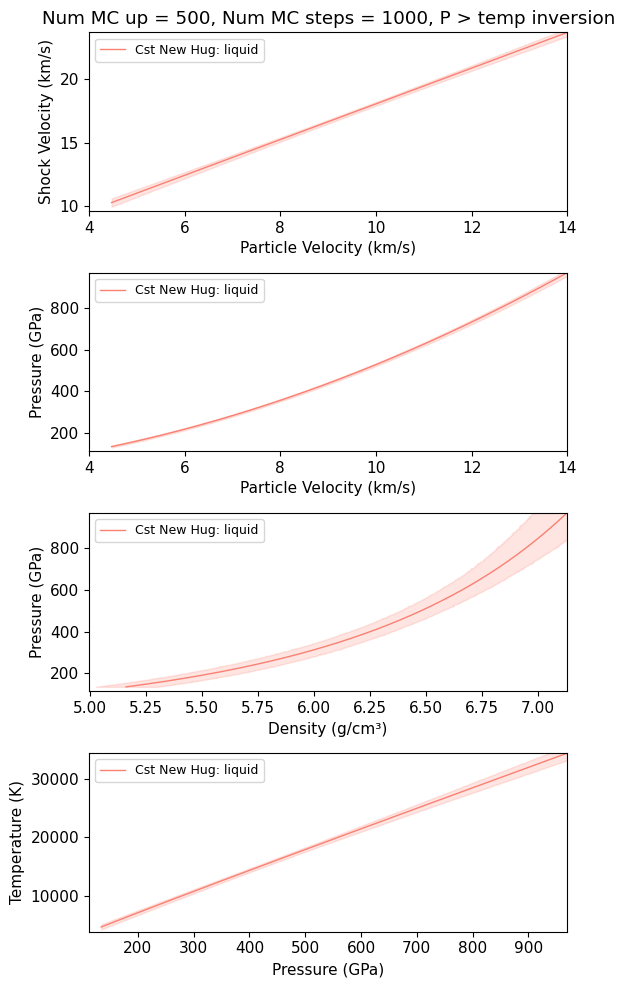

In [17]:
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
fig, ax = plt.subplots(4, 1,figsize=fsize5)
plt.rcParams['lines.markersize'] = mks


cst_mc = mc_list[3]

xi=0
ind = np.where(cst_hug_liq.P > cst_wiggle_P2)
ax[xi].plot(cst_hug_liq.up[ind],cst_hug_liq.us[ind],'-',color='salmon',label='Cst New Hug: liquid',linewidth=1)
ax[xi].fill_between(cst_hug_liq.up[ind],cst_hug_liq.us[ind]-cst_hug_liq.us_std[ind],cst_hug_liq.us[ind]+cst_hug_liq.us_std[ind],color='salmon',alpha=.2)
#ind = np.where(cst_mc.p_mean > cst_wiggle_P2)
#ax[xi].fill_between(cst_mc.up_ind[ind],cst_mc.p_mean[ind]-cst_mc.p_std[ind],cst_mc.p_mean[ind]+cst_mc.p_std[ind],color='black',alpha=.2)
ax[xi].set_xlim(min(cst_mc.up_ind),max(cst_mc.up_ind))
ax[xi].set_ylim(min(cst_mc.us_mean),max(cst_mc.us_mean))
ax[xi].set_ylabel('Shock Velocity (km/s)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].set_title('Num MC up = '+str(len(cst_mc.up_ind))+', Num MC steps = '+str(cst_mc.npts)+', P > temp inversion')
ax[xi].legend(fontsize=lfss)

xi=1
ind = np.where(cst_hug_liq.P > cst_wiggle_P2)
ax[xi].plot(cst_hug_liq.up[ind],cst_hug_liq.P[ind],'-',color='salmon',label='Cst New Hug: liquid',linewidth=1)
ax[xi].fill_between(cst_hug_liq.up[ind],cst_hug_liq.P[ind]-cst_hug_liq.P_std[ind],cst_hug_liq.P[ind]+cst_hug_liq.P_std[ind],color='salmon',alpha=.2)
#ind = np.where(cst_mc.p_mean > cst_wiggle_P2)
#ax[xi].fill_between(cst_mc.up_ind[ind],cst_mc.p_mean[ind]-cst_mc.p_std[ind],cst_mc.p_mean[ind]+cst_mc.p_std[ind],color='black',alpha=.2)
ax[xi].set_xlim(min(cst_mc.up_ind),max(cst_mc.up_ind))
ax[xi].set_ylim(min(cst_mc.p_mean),max(cst_mc.p_mean))
ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
#ax[xi].set_title('Num MC up = '+str(len(cst_mc.up_ind))+', Num MC steps = '+str(cst_mc.npts)+', P > temp inversion')
ax[xi].legend(fontsize=lfss)

xi=2
ind = np.where(cst_hug_liq.P > cst_wiggle_P2)
ax[xi].plot(cst_hug_liq.rho[ind],cst_hug_liq.P[ind],'-',color='salmon',linewidth=1,label='Cst New Hug: liquid')
ax[xi].fill_betweenx(cst_hug_liq.P[ind],cst_hug_liq.rho[ind]-cst_hug_liq.rho_std[ind],cst_hug_liq.rho[ind]+cst_hug_liq.rho_std[ind],color='salmon',alpha=.2)
#ind = np.where(cst_mc.p_mean > cst_wiggle_P2)
#ax[xi].fill_betweenx(cst_mc.p_mean[ind],cst_mc.rho_mean[ind]-cst_mc.rho_std[ind],cst_mc.rho_mean[ind]+cst_mc.rho_std[ind],color='black',alpha=.2)

ax[xi].set_xlim(min(cst_mc.rho_mean),max(cst_mc.rho_mean))
ax[xi].set_ylim(min(cst_mc.p_mean),max(cst_mc.p_mean))
ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Density (g/cm³)')
ax[xi].legend(fontsize=lfss)


xi=3
ind = np.where(cst_hug_liq.P > cst_wiggle_P2)
ax[xi].plot(cst_hug_liq.P[ind],cst_hug_liq.T[ind],'-',color='salmon',label='Cst New Hug: liquid',linewidth=1)
ax[xi].fill_between(cst_hug_liq.P[ind],cst_hug_liq.T[ind]-cst_hug_liq.T_std[ind],cst_hug_liq.T[ind]+cst_hug_liq.T_std[ind],color='salmon',alpha=.2)

#ind = np.where(cst_mc.p_mean > cst_wiggle_P2)
#ax[xi].fill_between(cst_mc.p_mean[ind],cst_mc.t_mean[ind]-cst_mc.t_std[ind],cst_mc.t_mean[ind]+cst_mc.t_std[ind],color='black',alpha=0.2)

ax[xi].set_ylim(min(cst_mc.t_mean),max(cst_mc.t_mean))
ax[xi].set_xlim(min(cst_mc.p_mean),max(cst_mc.p_mean))

ax[xi].set_xlabel('Pressure (GPa)')
ax[xi].set_ylabel('Temperature (K)')
ax[xi].legend(fontsize=lfss)

fig.tight_layout()
plt.savefig(outputfigpath+tag+'cst-mc-uncertainties.pdf')
plt.show()

## Stishovite Hugoniot -- liquid region sensitivity tests

In [18]:

print('Reference density = ',stv_fit_liq0.rho_ref)
print('Reference density uncertainty = ',stv_fit_liq0.rho_ref_std)
upus_fit = deepcopy(stv_fit_liq0)
ust_fit = deepcopy(stv_fitTus_liq0)
## define_eos.py range stv_hug_liq.up = np.arange(5,20,.01) # km/s
upmin=5
upmax=20


Reference density =  4.29
Reference density uncertainty =  0.03


In [19]:
import time

print('Stishovite PTV Hugoniot Monte-Carlo uncertainties')
nsteps = [10,100,500,1000,2000]
nupind = 500#200
print('number of up points = ',nupind)
mc_list =  []
for ii in range(len(nsteps)):
    start_time = time.perf_counter()

    dat_mc = HPeos_MC()
    dat_mc.npts = nsteps[ii]
    
    mcuparr = np.linspace(upmin,upmax,nupind)
    dat_mc.up_ind = mcuparr 
    dat_mc.calcMC(upus_fit,ust_fit,verbose=False)

    end_time = time.perf_counter()
    print('Time: ',nsteps[ii],end_time - start_time)

    mc_list.append(deepcopy(dat_mc))
    

Stishovite PTV Hugoniot Monte-Carlo uncertainties
number of up points =  500
Time:  10 0.07040149997919798
Time:  100 0.398437375202775
Time:  500 1.8060967922210693
Time:  1000 3.5408212919719517
Time:  2000 7.062736709136516


<Figure size 800x600 with 0 Axes>

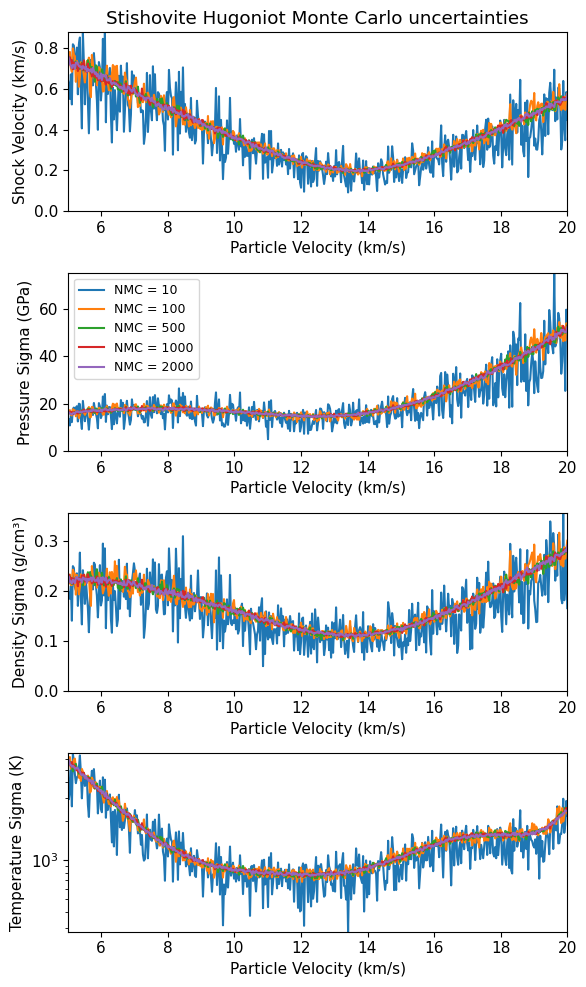

In [20]:
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
fig, ax = plt.subplots(4, 1,figsize=fsize5)
plt.rcParams['lines.markersize'] = mks

maxp=0
maxr=0
maxt=0
mint=10000
maxus=0

minup = min(mc_list[0].up_ind)
maxup = max(mc_list[0].up_ind)
for ii in range(len(mc_list)):

    xi=0
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].us_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].us_std)>maxus:
        maxus=max(mc_list[ii].us_std)
        
    xi=1
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].p_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].p_std)>maxp:
        maxp=max(mc_list[ii].p_std)
    xi=2
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].rho_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].rho_std)>maxr:
        maxr=max(mc_list[ii].rho_std)    
    xi=3
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].t_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].t_std)>maxt:
        maxt=max(mc_list[ii].t_std)       
    if min(mc_list[ii].t_std)<mint:
        mint=min(mc_list[ii].t_std)       

xi=0
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxus)
ax[xi].set_ylabel('Shock Velocity (km/s)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].set_title('Stishovite Hugoniot Monte Carlo uncertainties')


xi=1
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxp)
ax[xi].set_ylabel('Pressure Sigma (GPa)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].legend(fontsize=lfss)

xi=2
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxr)
ax[xi].set_ylabel('Density Sigma (g/cm³)')
ax[xi].set_xlabel('Particle Velocity (km/s)')


xi=3
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(mint,maxt)
ax[xi].set_yscale('log')
ax[xi].set_ylabel('Temperature Sigma (K)')
ax[xi].set_xlabel('Particle Velocity (km/s)')



fig.tight_layout()
plt.savefig(outputfigpath+tag+'stv-mc-sensitivity.pdf')
plt.show()

In [21]:
## After picking the desired resolution, interpolate the uncertainties into the master hugoniot array
## This is for fast loading. Can modify as desired using the MC hpeos module function

# choose index for interpolation
imc=3
print('MC nup, nsteps=',len(mc_list[imc].up_ind),mc_list[imc].npts)
stv_hug_liq.us_std = np.interp(stv_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].us_std)
stv_hug_liq.P_std = np.interp(stv_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].p_std)
stv_hug_liq.T_std = np.interp(stv_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].t_std)
stv_hug_liq.rho_std = np.interp(stv_hug_liq.up,mc_list[imc].up_ind,mc_list[imc].rho_std)


MC nup, nsteps= 500 1000


<Figure size 800x600 with 0 Axes>

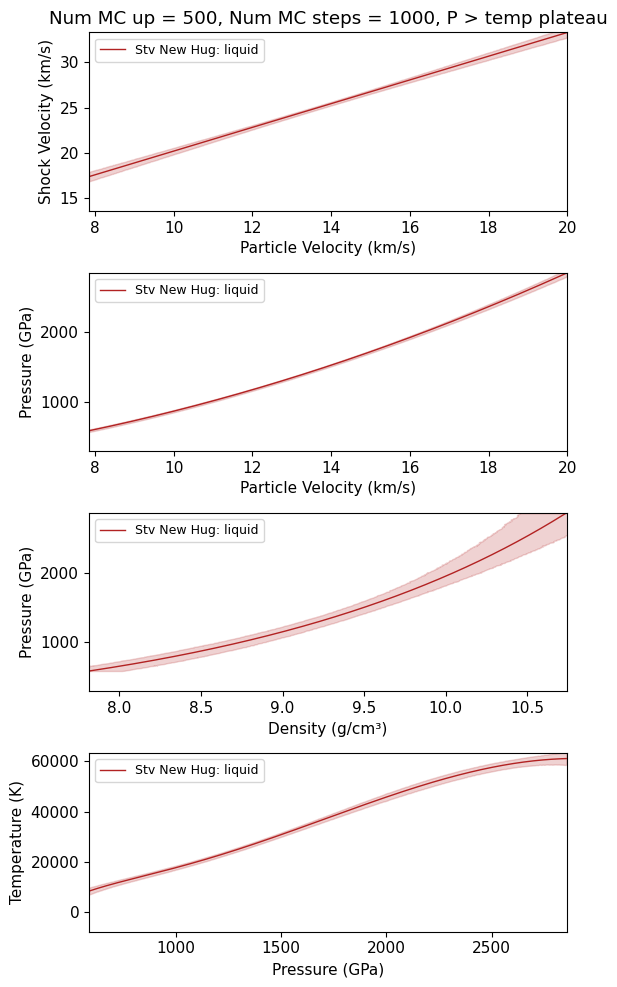

In [24]:
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
fig, ax = plt.subplots(4, 1,figsize=fsize5)
plt.rcParams['lines.markersize'] = mks

stv_mc = mc_list[3]
minup=stv_wiggle2.up
maxup=max(stv_mc.up_ind)

xi=0
ind = np.where(stv_hug_liq.P > stv_wiggle2.P)
ax[xi].plot(stv_hug_liq.up[ind],stv_hug_liq.us[ind],'-',color='firebrick',label='Stv New Hug: liquid',linewidth=1)
ax[xi].fill_between(stv_hug_liq.up[ind],stv_hug_liq.us[ind]-stv_hug_liq.us_std[ind],stv_hug_liq.us[ind]+stv_hug_liq.us_std[ind],color='firebrick',alpha=.2)
#ind = np.where(stv_mc.p_mean > stv_wiggle2.P)
#ax[xi].fill_between(stv_mc.up_ind[ind],stv_mc.p_mean[ind]-stv_mc.p_std[ind],stv_mc.p_mean[ind]+stv_mc.p_std[ind],color='black',alpha=.2)
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(min(stv_mc.us_mean),max(stv_mc.us_mean))
ax[xi].set_ylabel('Shock Velocity (km/s)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].set_title('Num MC up = '+str(len(stv_mc.up_ind))+', Num MC steps = '+str(stv_mc.npts)+', P > temp plateau')
ax[xi].legend(fontsize=lfss)

xi=1
ind = np.where(stv_hug_liq.P > stv_wiggle2.P)
ax[xi].plot(stv_hug_liq.up[ind],stv_hug_liq.P[ind],'-',color='firebrick',label='Stv New Hug: liquid',linewidth=1)
ax[xi].fill_between(stv_hug_liq.up[ind],stv_hug_liq.P[ind]-stv_hug_liq.P_std[ind],stv_hug_liq.P[ind]+stv_hug_liq.P_std[ind],color='firebrick',alpha=.2)
#ind = np.where(stv_mc.p_mean > stv_wiggle2.P)
#ax[xi].fill_between(stv_mc.up_ind[ind],stv_mc.p_mean[ind]-stv_mc.p_std[ind],stv_mc.p_mean[ind]+stv_mc.p_std[ind],color='black',alpha=.2)
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(min(stv_mc.p_mean),max(stv_mc.p_mean))
ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
#ax[xi].set_title('Num MC up = '+str(len(stv_mc.up_ind))+', Num MC steps = '+str(stv_mc.npts)+', P > temp inversion')
ax[xi].legend(fontsize=lfss)

xi=2
ind = np.where(stv_hug_liq.P > stv_wiggle2.P)
ax[xi].plot(stv_hug_liq.rho[ind],stv_hug_liq.P[ind],'-',color='firebrick',linewidth=1,label='Stv New Hug: liquid')
ax[xi].fill_betweenx(stv_hug_liq.P[ind],stv_hug_liq.rho[ind]-stv_hug_liq.rho_std[ind],stv_hug_liq.rho[ind]+stv_hug_liq.rho_std[ind],color='firebrick',alpha=.2)
#ind = np.where(stv_mc.p_mean > stv_wiggle2.P)
#ax[xi].fill_betweenx(stv_mc.p_mean[ind],stv_mc.rho_mean[ind]-stv_mc.rho_std[ind],stv_mc.rho_mean[ind]+stv_mc.rho_std[ind],color='black',alpha=.2)

ax[xi].set_xlim(stv_wiggle2.rho,max(stv_mc.rho_mean))
ax[xi].set_ylim(min(stv_mc.p_mean),max(stv_mc.p_mean))
ax[xi].set_ylabel('Pressure (GPa)')
ax[xi].set_xlabel('Density (g/cm³)')
ax[xi].legend(fontsize=lfss)


xi=3
ind = np.where(stv_hug_liq.P > stv_wiggle2.P)
ax[xi].plot(stv_hug_liq.P[ind],stv_hug_liq.T[ind],'-',color='firebrick',label='Stv New Hug: liquid',linewidth=1)
ax[xi].fill_between(stv_hug_liq.P[ind],stv_hug_liq.T[ind]-stv_hug_liq.T_std[ind],stv_hug_liq.T[ind]+stv_hug_liq.T_std[ind],color='firebrick',alpha=.2)

#ind = np.where(stv_mc.p_mean > stv_wiggle2.P)
#ax[xi].fill_between(stv_mc.p_mean[ind],stv_mc.t_mean[ind]-stv_mc.t_std[ind],stv_mc.t_mean[ind]+stv_mc.t_std[ind],color='black',alpha=0.2)

ax[xi].set_ylim(min(stv_mc.t_mean),max(stv_mc.t_mean+stv_mc.t_std))
ax[xi].set_xlim(stv_wiggle2.P,max(stv_mc.p_mean))

ax[xi].set_xlabel('Pressure (GPa)')
ax[xi].set_ylabel('Temperature (K)')
ax[xi].legend(fontsize=lfss)

fig.tight_layout()
plt.savefig(outputfigpath+tag+'stv-mc-uncertainties.pdf')
plt.show()